In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram,linkage

In [2]:
df=pd.read_csv("Hitters.csv")
df.head(5)

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


In [32]:
df['State']=df['State'].map({
    "New York":0,
    "California":1,
    "Florida":2
})

print(df.head(5))

   R&D Spend  Administration  Marketing Spend  State     Profit
0  165349.20       136897.80        471784.10      0  192261.83
1  162597.70       151377.59        443898.53      1  191792.06
2  153441.51       101145.55        407934.54      2  191050.39
3  144372.41       118671.85        383199.62      0  182901.99
4  142107.34        91391.77        366168.42      2  166187.94


In [47]:
df=df.dropna()

df.head(5)

from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()

for col in df.columns:
    if df[col].dtypes=='object':
        df[col]=le.fit_transform(df[col])

In [5]:
X=df[['AtBat','Hits']]

In [6]:
scaler=StandardScaler()

x_scaled=scaler.fit_transform(X)

0.6004455295934529
0.5257138088652136
0.49075068974068425
0.48382970516230456
0.5090336838978863
0.4989422279197199
0.4675444899819722
0.460222092889344
0.44031128815646137
[184.49478647047272, 101.06187097626685, 66.8836137873862, 48.61568999248986, 34.493323645618744, 26.666209491023935, 22.195558079233184, 19.106043881959344, 16.047456032197193]


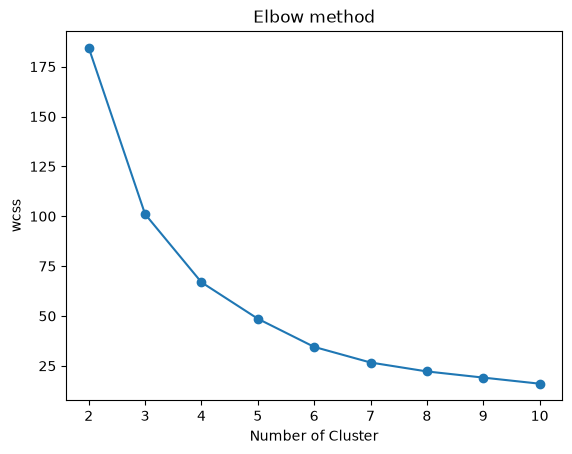

In [7]:
# kmeans
# clustering
from sklearn.metrics import silhouette_score
wcss=[]

for i in range(2,11):
    kmeans=KMeans(n_clusters=i,n_init=10,random_state=42)
    kmeans.fit(x_scaled)
    labels=kmeans.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, labels)
    print(score)

    wcss.append(kmeans.inertia_)

print(wcss)

#plot graph
plt.plot(range(2,11),wcss,marker='o')
plt.title("Elbow method")
plt.xlabel("Number of Cluster")
plt.ylabel("wcss")
plt.show()

In [10]:
Kmeans=KMeans(n_clusters=3,random_state=42)
kmeans.fit(x_scaled)
kmeans_labels=kmeans.fit_predict(x_scaled)

print(silhouette_score(x_scaled, kmeans_labels))

0.44031128815646137


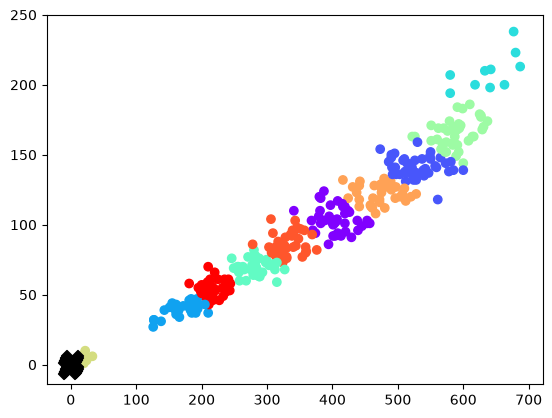

In [9]:
# plt.scatter(X['R&D Spend'],X['Profit'],c=kmeans_labels,cmap="rainbow")
# plt.show()

centroids=kmeans.cluster_centers_

plt.scatter(X['AtBat'],X['Hits'],c=kmeans_labels,cmap="rainbow")
plt.scatter(centroids[:, 0],
    centroids[:, 1],
    color='black',
    marker='X',
    s=250,
    label='Centroids'
)
plt.show()

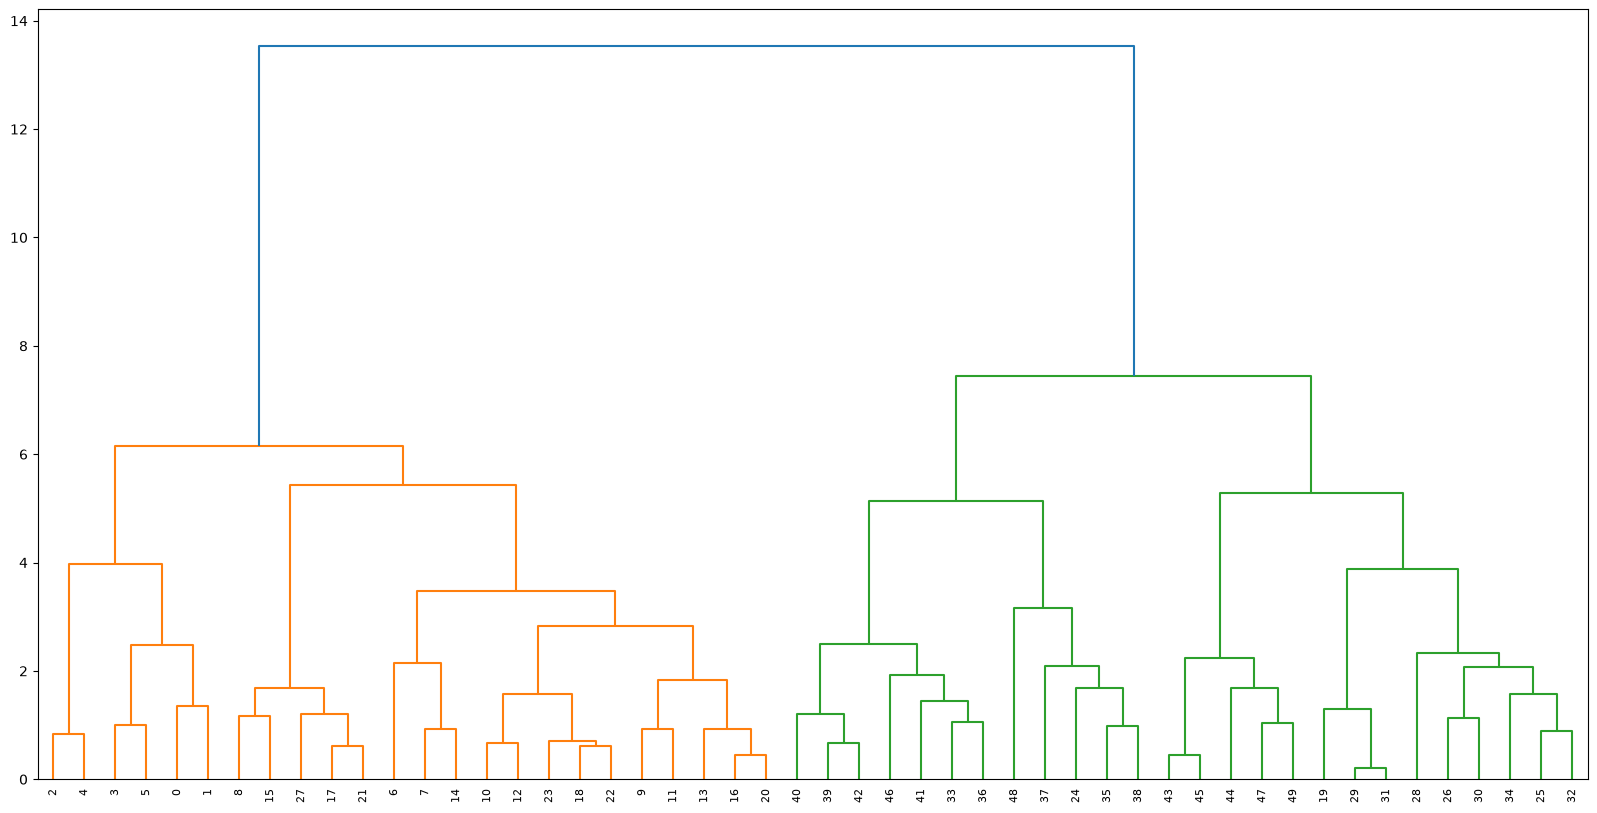

0.2783369141509234


In [13]:
# heirarchical 
# create dendrogram
linked=linkage(x_scaled,metric='euclidean',method="ward")
plt.figure(figsize=(20,10))
dendrogram(linked)
plt.show()
hc=AgglomerativeClustering(n_clusters=5)
hc_labels=hc.fit_predict(x_scaled)

print(silhouette_score(x_scaled, kmeans_labels))

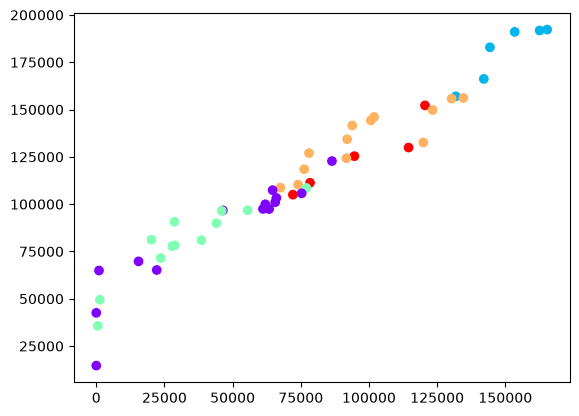

In [14]:
# plt.scatter(X['R&D Spend'],X['Profit'],c=hc_labels,cmap="rainbow")
plt.show()

In [56]:
import seaborn as sns
data=sns.load_dataset('iris')

URLError: <urlopen error [WinError 10065] A socket operation was attempted to an unreachable host>

In [ ]:
print(data.head(5)